[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Prasathn01/wattwise-ml/blob/main/notebooks/PBL2_Units3_4.ipynb)

# WattWise: PBL-II working model (Units 3 & 4), from scratch
**21CSC305P Machine Learning · Team 4 · Household Energy Consumption Analysis & Peak-Load Prediction**

Every algorithm is coded directly from the equations in our *Mathematical Model* document. No machine-learning library is used:
* **NumPy** only for arrays and matrix operations (matrix product, solving a linear system, eigen-decomposition, Cholesky factor).
* **pandas** only to read the CSV file and average minutes into hours.
* **matplotlib** only for plots.

| Section | Content |
|---|---|
| 1–2 | Load the data; exploratory data analysis |
| 3–8 | **Unit 3:** daily load profiles → K-means, GMM + EM, PCA, factor analysis, hierarchical clustering, silhouette, Davies–Bouldin, ARI |
| 9–14 | **Unit 4:** hourly load sequence → Markov chain, HMM (Baum–Welch with scaled forward–backward), Viterbi, Kalman filter and smoother (EM), next-hour comparison against baselines |

**How to run:** Google Colab → *Runtime → Run all* (about 5 minutes). Figures are saved to `figures/`, numbers to `results.json`.

In [1]:
import os, json, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
FIG = "figures"
os.makedirs(FIG, exist_ok=True)
RESULTS = {}

def savefig(name):
    plt.tight_layout()
    plt.savefig(f"{FIG}/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

def show(df):
    # print a table without extra libraries
    print(df.to_string(index=False))

COLORS = ["#2b6cb0", "#dd6b20", "#2f855a", "#c53030", "#6b46c1", "#975a16", "#b83280", "#4a5568"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

## 1. Load the data and make hourly load
An hour is kept only if at least 45 of its 60 minutes were recorded. Its value is the mean kW of those minutes.

In [2]:
DATA_URL = "https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip"
DATA_TXT = "household_power_consumption.txt"
if not os.path.exists(DATA_TXT):
    urllib.request.urlretrieve(DATA_URL, "hpc.zip")
    with zipfile.ZipFile("hpc.zip") as z:
        z.extract(DATA_TXT)

raw = pd.read_csv(DATA_TXT, sep=";", na_values="?", usecols=["Date", "Time", "Global_active_power"], low_memory=False)
raw.index = pd.to_datetime(raw["Date"] + " " + raw["Time"], format="%d/%m/%Y %H:%M:%S")
power = raw["Global_active_power"].astype(float)

hourly = power.resample("h").mean()
hourly[power.resample("h").count() < 45] = np.nan

print(f"Minute readings: {len(power):,} ({power.isna().mean():.2%} missing), {power.index.min()} to {power.index.max()}")
print(f"Hours kept: {hourly.notna().sum():,} of {len(hourly):,}")
RESULTS["n_minutes"] = int(len(power)); RESULTS["missing_minutes_pct"] = round(100 * float(power.isna().mean()), 2)

Minute readings: 2,075,259 (1.25% missing), 2006-12-16 17:24:00 to 2010-11-26 21:02:00
Hours kept: 34,151 of 34,589


## 2. Exploratory data analysis
What does the household's load look like, and how strongly does one hour depend on the previous ones? The autocorrelation answers the second question and is the reason Unit 4's sequence models make sense.

Hourly load: mean 1.092 kW, median 0.803 kW, sd 0.898 kW, skewness 1.30
Busiest hour (weekdays): 21:00 at 1.86 kW; quietest: 3:00 at 0.41 kW
Highest month: 12 (1.49 kW); lowest month: 8 (0.57 kW)
Autocorrelation: 1 hour 0.71, 24 hours 0.44, 168 hours (1 week) 0.46


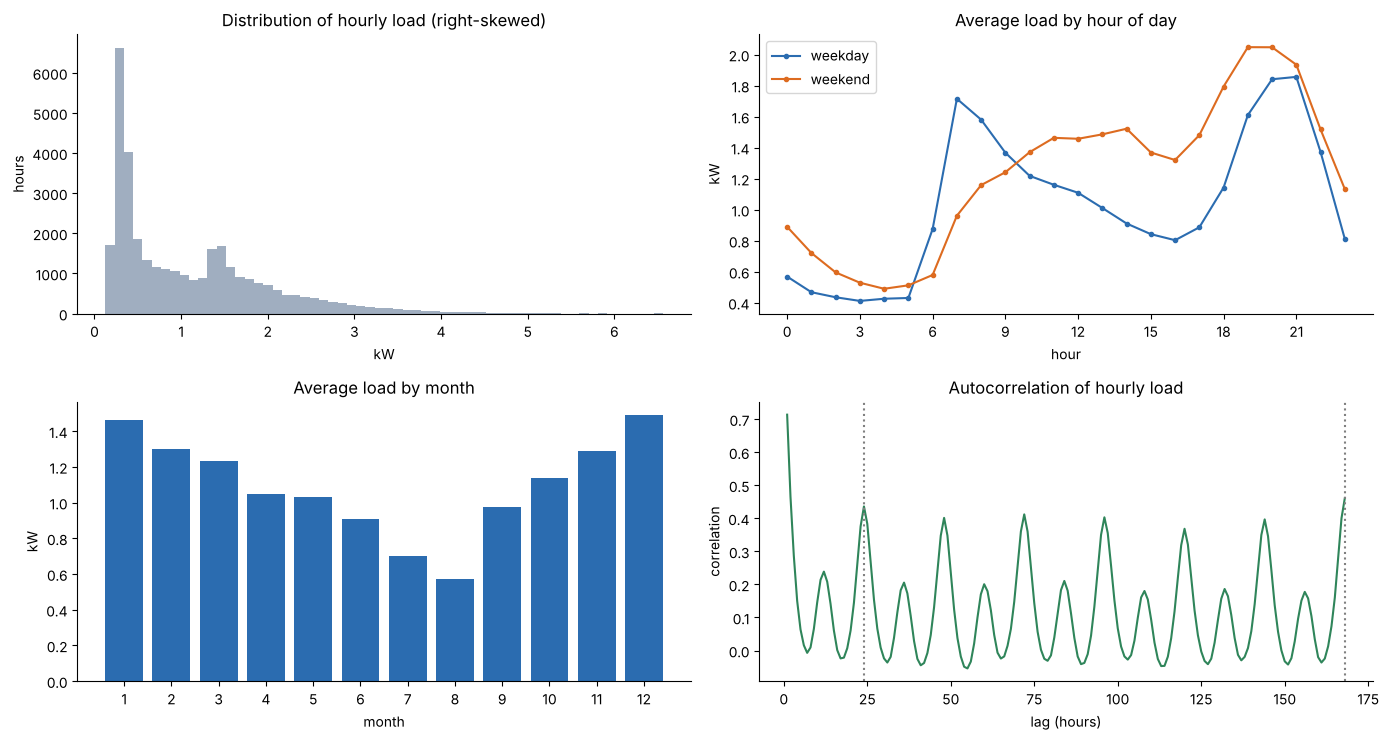

In [3]:
hv = hourly.dropna()
def autocorr(series, lag):
    x = series.values
    a, b = x[:-lag], x[lag:]
    ok = ~np.isnan(a) & ~np.isnan(b)
    return float(np.corrcoef(a[ok], b[ok])[0, 1])

lags = np.arange(1, 169)
acf = np.array([autocorr(hourly, k) for k in lags])
skew = float(((hv - hv.mean()) ** 3).mean() / hv.std() ** 3)
by_hour_wd = hv[hv.index.dayofweek < 5].groupby(hv[hv.index.dayofweek < 5].index.hour).mean()
by_hour_we = hv[hv.index.dayofweek >= 5].groupby(hv[hv.index.dayofweek >= 5].index.hour).mean()
by_month = hv.groupby(hv.index.month).mean()

print(f"Hourly load: mean {hv.mean():.3f} kW, median {hv.median():.3f} kW, sd {hv.std():.3f} kW, skewness {skew:.2f}")
print(f"Busiest hour (weekdays): {int(by_hour_wd.idxmax())}:00 at {by_hour_wd.max():.2f} kW; quietest: {int(by_hour_wd.idxmin())}:00 at {by_hour_wd.min():.2f} kW")
print(f"Highest month: {int(by_month.idxmax())} ({by_month.max():.2f} kW); lowest month: {int(by_month.idxmin())} ({by_month.min():.2f} kW)")
print(f"Autocorrelation: 1 hour {acf[0]:.2f}, 24 hours {acf[23]:.2f}, 168 hours (1 week) {acf[167]:.2f}")
RESULTS["eda"] = {"mean_kW": round(float(hv.mean()), 3), "median_kW": round(float(hv.median()), 3), "sd_kW": round(float(hv.std()), 3),
                  "skewness": round(skew, 2), "peak_hour_weekday": int(by_hour_wd.idxmax()), "acf_1h": round(acf[0], 3),
                  "acf_24h": round(acf[23], 3), "acf_168h": round(acf[167], 3)}

fig, ax = plt.subplots(2, 2, figsize=(14, 7.5))
ax[0, 0].hist(hv.values, bins=60, color="#a0aec0"); ax[0, 0].set(title="Distribution of hourly load (right-skewed)", xlabel="kW", ylabel="hours")
ax[0, 1].plot(by_hour_wd.index, by_hour_wd.values, "o-", ms=3, color=COLORS[0], label="weekday")
ax[0, 1].plot(by_hour_we.index, by_hour_we.values, "o-", ms=3, color=COLORS[1], label="weekend")
ax[0, 1].set(title="Average load by hour of day", xlabel="hour", ylabel="kW"); ax[0, 1].set_xticks(range(0, 24, 3)); ax[0, 1].legend()
ax[1, 0].bar(by_month.index, by_month.values, color=COLORS[0]); ax[1, 0].set(title="Average load by month", xlabel="month", ylabel="kW"); ax[1, 0].set_xticks(range(1, 13))
ax[1, 1].plot(lags, acf, color=COLORS[2]); ax[1, 1].axvline(24, ls=":", color="grey"); ax[1, 1].axvline(168, ls=":", color="grey")
ax[1, 1].set(title="Autocorrelation of hourly load", xlabel="lag (hours)", ylabel="correlation")
savefig("eda_overview")

---
# Unit 3: what kinds of days does the household have?
## 3. Daily profiles, standardisation, dissimilarity
x_n ∈ ℝ²⁴ = the 24 hourly loads of day n (complete days only). Each hour column is standardised. Squared Euclidean distance between all pairs is computed with ||a − b||² = ||a||² + ||b||² − 2aᵀb.

In [4]:
hd = hourly.to_frame("kW")
hd["date"] = hd.index.normalize(); hd["hour"] = hd.index.hour
profiles = hd.pivot(index="date", columns="hour", values="kW").dropna()
P = profiles.values
p_mean, p_sd = P.mean(0), P.std(0)
Xd = (P - p_mean) / p_sd
daily_kwh = P.sum(1)
print(f"Complete days: {len(Xd):,}")
RESULTS["n_days"] = int(len(Xd))

def sq_dists(A, B):
    return np.maximum((A ** 2).sum(1)[:, None] + (B ** 2).sum(1)[None, :] - 2 * A @ B.T, 0.0)

D_eu = np.sqrt(sq_dists(Xd, Xd))           # used by silhouette and the hierarchical methods

Complete days: 1,411


## 4. K-means and the evaluation measures

In [5]:
def kmeans_pp_init(X, K, rng):
    C = [X[rng.integers(len(X))]]
    for _ in range(1, K):
        d2 = sq_dists(X, np.array(C)).min(1)
        C.append(X[rng.choice(len(X), p=d2 / d2.sum())])     # next centre chosen with probability proportional to D(x)^2
    return np.array(C)

def kmeans(X, K, rng, n_init=20, max_iter=300):
    best = None
    for _ in range(n_init):
        C = kmeans_pp_init(X, K, rng); hist = []
        for _ in range(max_iter):
            d2 = sq_dists(X, C)
            lab = d2.argmin(1)                                 # assignment step
            hist.append(float(d2[np.arange(len(X)), lab].sum()))   # J = sum ||x_n - mu_k||^2
            C_new = np.array([X[lab == k].mean(0) if np.any(lab == k) else C[k] for k in range(K)])   # update step
            if np.allclose(C_new, C): break
            C = C_new
        d2 = sq_dists(X, C); lab = d2.argmin(1); J = float(d2[np.arange(len(X)), lab].sum())
        if best is None or J < best[2]:
            best = (lab, C, J, hist)
    return best

def silhouette(D, lab):
    ks = np.unique(lab); onehot = (lab[:, None] == ks[None, :]).astype(float)
    cnt = onehot.sum(0)
    sums = D @ onehot                                           # sum of distances from each point to each cluster
    own = np.searchsorted(ks, lab)
    a = sums[np.arange(len(lab)), own] / np.maximum(cnt[own] - 1, 1)
    mean_other = sums / cnt; mean_other[np.arange(len(lab)), own] = np.inf
    b = mean_other.min(1)
    s = (b - a) / np.maximum(a, b)
    s[cnt[own] == 1] = 0.0
    return float(s.mean())

def davies_bouldin(X, lab):
    ks = np.unique(lab)
    C = np.array([X[lab == k].mean(0) for k in ks])
    S = np.array([np.sqrt(((X[lab == k] - C[i]) ** 2).sum(1)).mean() for i, k in enumerate(ks)])
    M = np.sqrt(sq_dists(C, C)); np.fill_diagonal(M, np.inf)
    R = (S[:, None] + S[None, :]) / M
    return float(R.max(1).mean())

def adjusted_rand(a, b):
    _, ai = np.unique(a, return_inverse=True); _, bi = np.unique(b, return_inverse=True)
    T = np.zeros((ai.max() + 1, bi.max() + 1)); np.add.at(T, (ai, bi), 1)
    c2 = lambda x: x * (x - 1) / 2
    sum_ij, sum_a, sum_b, tot = c2(T).sum(), c2(T.sum(1)).sum(), c2(T.sum(0)).sum(), c2(len(a))
    exp = sum_a * sum_b / tot
    return float((sum_ij - exp) / (0.5 * (sum_a + sum_b) - exp))

 K  J (inertia)  silhouette  Davies-Bouldin
 2      28070.8      0.2026          2.0562
 3      24371.3      0.1641          1.7707
 4      22109.4      0.1346          1.9017
 5      21079.5      0.1331          2.0769
 6      20184.9      0.1282          2.0367
 7      19413.4      0.0937          2.0818
 8      18748.0      0.0932          2.0706
Silhouette picks K = 2; using K = 2


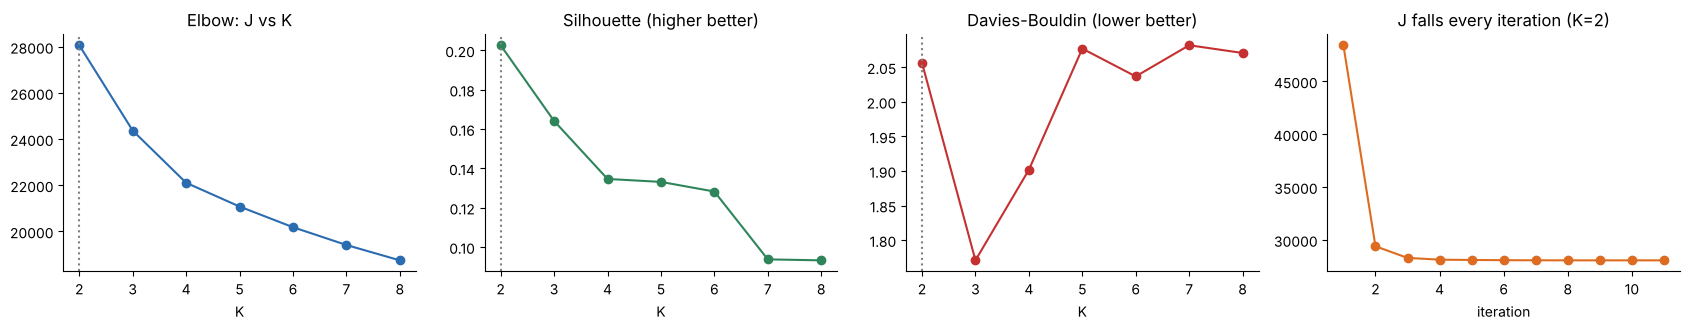

In [6]:
rows = []
for k in range(2, 9):
    lab_k, _, J_k, _ = kmeans(Xd, k, rng)
    rows.append({"K": k, "J (inertia)": round(J_k, 1), "silhouette": round(silhouette(D_eu, lab_k), 4), "Davies-Bouldin": round(davies_bouldin(Xd, lab_k), 4)})
kdf = pd.DataFrame(rows); show(kdf)

K_AUTO = int(kdf.loc[kdf["silhouette"].idxmax(), "K"])
K_OVERRIDE = None          # set a number here if the team picks a different K; give the reason in the review
K = K_OVERRIDE or K_AUTO
print(f"Silhouette picks K = {K_AUTO}; using K = {K}")
RESULTS["K"] = K; RESULTS["k_selection"] = kdf.to_dict(orient="records")

def by_usage(lab):
    # renumber clusters so 0 = lowest mean daily kWh, for every method
    order = np.argsort([daily_kwh[lab == k].mean() for k in range(lab.max() + 1)])
    remap = np.empty_like(order); remap[order] = np.arange(len(order))
    return remap[lab]

lab_km, C_km, J_km, hist_km = kmeans(Xd, K, rng)
lab_km = by_usage(lab_km)

fig, ax = plt.subplots(1, 4, figsize=(17, 3.4))
ax[0].plot(kdf["K"], kdf["J (inertia)"], "o-", color=COLORS[0]); ax[0].set(title="Elbow: J vs K", xlabel="K")
ax[1].plot(kdf["K"], kdf["silhouette"], "o-", color=COLORS[2]); ax[1].set(title="Silhouette (higher better)", xlabel="K")
ax[2].plot(kdf["K"], kdf["Davies-Bouldin"], "o-", color=COLORS[3]); ax[2].set(title="Davies-Bouldin (lower better)", xlabel="K")
for a_ in ax[:3]: a_.axvline(K, ls=":", color="grey")
ax[3].plot(range(1, len(hist_km) + 1), hist_km, "o-", color=COLORS[1]); ax[3].set(title=f"J falls every iteration (K={K})", xlabel="iteration")
savefig("u3_kmeans")

## 5. Gaussian mixture model fitted with EM
E-step: responsibilities γ_nk = π_k N(x_n|μ_k, Σ_k) / Σ_j π_j N(x_n|μ_j, Σ_j). M-step: N_k = Σ_n γ_nk, π_k = N_k/N, μ_k = Σ_n γ_nk x_n / N_k, Σ_k = Σ_n γ_nk (x_n − μ_k)(x_n − μ_k)ᵀ / N_k (+ 10⁻⁶ I for numerical stability). Started from the K-means labels. BIC = −2 ln L + p ln N chooses full vs diagonal covariance.

BIC: {'full': 70813, 'diag': 85694} -> using full
EM iterations: 106; log-likelihood never decreased: True
Days with max responsibility below 0.9 (in between two kinds of day): 2.7%


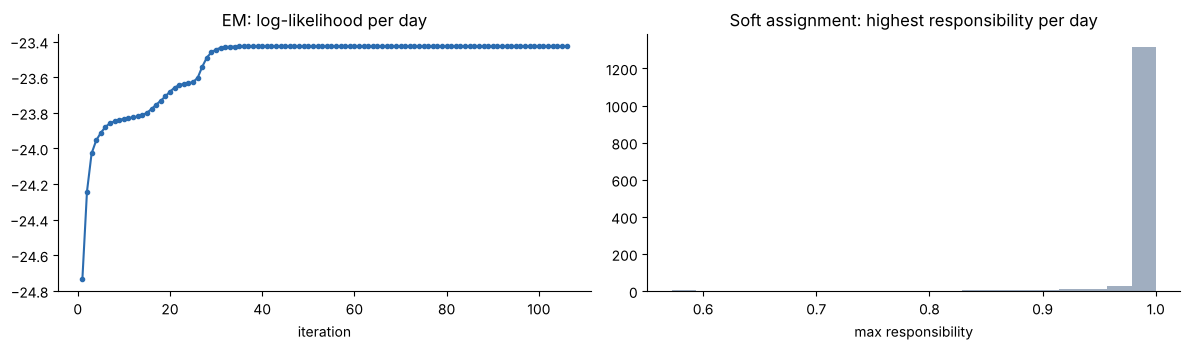

In [7]:
def log_gauss(X, mu, Sigma):
    Lc = np.linalg.cholesky(Sigma)
    z = np.linalg.solve(Lc, (X - mu).T)
    return -0.5 * (z ** 2).sum(0) - np.log(np.diag(Lc)).sum() - 0.5 * X.shape[1] * np.log(2 * np.pi)

def logsumexp(A):
    m = A.max(1, keepdims=True)
    return (m + np.log(np.exp(A - m).sum(1, keepdims=True)))[:, 0]

def gmm_em(X, K, init_lab, cov="full", max_iter=500, tol=1e-7, reg=1e-6):
    N, D = X.shape
    resp = (init_lab[:, None] == np.arange(K)[None, :]).astype(float)
    hist = []
    for _ in range(max_iter):
        Nk = resp.sum(0) + 1e-12                                       # M-step
        pi = Nk / N
        mu = (resp.T @ X) / Nk[:, None]
        Sig = []
        for k in range(K):
            d = X - mu[k]
            Sk = (resp[:, k, None] * d).T @ d / Nk[k]
            Sig.append((np.diag(np.diag(Sk)) if cov == "diag" else Sk) + reg * np.eye(D))
        logp = np.column_stack([np.log(pi[k]) + log_gauss(X, mu[k], Sig[k]) for k in range(K)])   # E-step
        ll = logsumexp(logp)
        resp = np.exp(logp - ll[:, None])
        hist.append(float(ll.mean()))
        if len(hist) > 1 and abs(hist[-1] - hist[-2]) < tol: break
    n_par = (K - 1) + K * D + K * (D if cov == "diag" else D * (D + 1) / 2)
    bic = -2 * ll.sum() + n_par * np.log(N)
    return pi, mu, Sig, resp, hist, float(bic)

fits = {c: gmm_em(Xd, K, lab_km, cov=c) for c in ["full", "diag"]}
COV = min(fits, key=lambda c: fits[c][5])
pi_g, mu_g, Sig_g, resp_g, hist_g, _ = fits[COV]
lab_gmm = by_usage(resp_g.argmax(1))
print("BIC:", {c: round(f[5]) for c, f in fits.items()}, "-> using", COV)
print(f"EM iterations: {len(hist_g)}; log-likelihood never decreased: {bool(np.all(np.diff(hist_g) >= -1e-9))}")
print(f"Days with max responsibility below 0.9 (in between two kinds of day): {(resp_g.max(1) < 0.9).mean():.1%}")
RESULTS["gmm"] = {"cov": COV, "em_iterations": len(hist_g), "uncertain_days_pct": round(100 * float((resp_g.max(1) < 0.9).mean()), 2)}

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(range(1, len(hist_g) + 1), hist_g, "o-", ms=3, color=COLORS[0]); ax[0].set(title="EM: log-likelihood per day", xlabel="iteration")
ax[1].hist(resp_g.max(1), bins=20, color="#a0aec0"); ax[1].set(title="Soft assignment: highest responsibility per day", xlabel="max responsibility")
savefig("u3_gmm_em")

## 6. PCA, factor analysis and the number of latent dimensions
PCA: covariance S = XᵀX/(N−1) of the standardised data, eigen-decomposition S u = λ u, keep the top k eigenvectors.
Factor analysis: x = W z + μ + ε, z ~ N(0, I), ε ~ N(0, Ψ) with Ψ diagonal, fitted by EM.
Number of dimensions is chosen three ways: 90 % cumulative variance, eigenvalue > 1, and the log-likelihood of held-out days (80/20 random split of days) under probabilistic PCA and under factor analysis.

PPCA picks more dimensions than factor analysis: PPCA gives every hour the SAME noise variance, so it must use extra components to explain hours that are simply noisier; FA gives each hour its own noise.
PC1 29.3%, PC2 14.6%, PC1+PC2 43.9% of variance
k for 90% variance: 14 | eigenvalue > 1: 6 | held-out PPCA: 15 | held-out factor analysis: 13


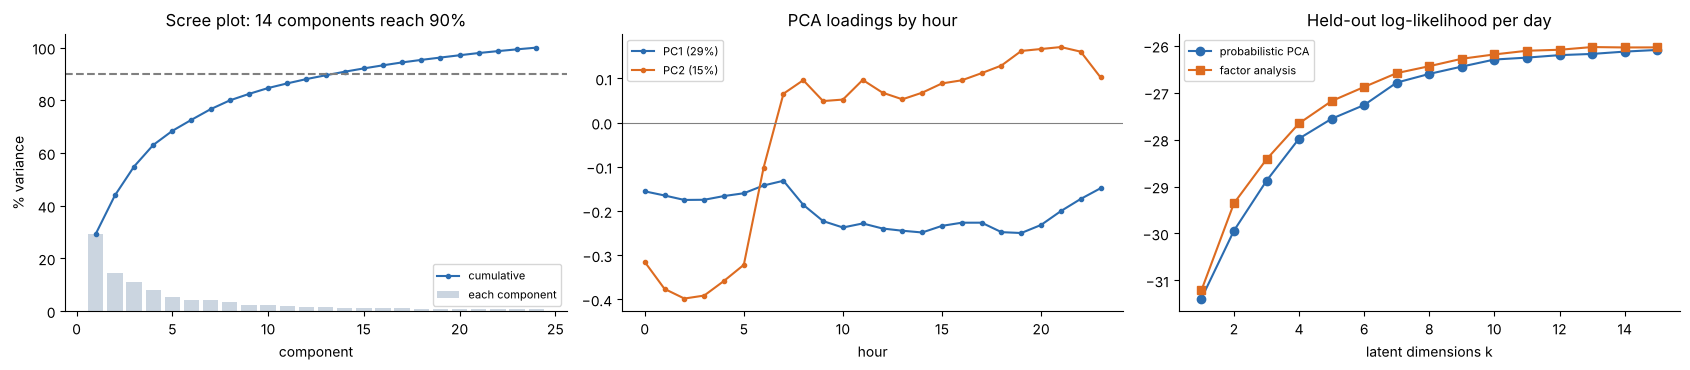

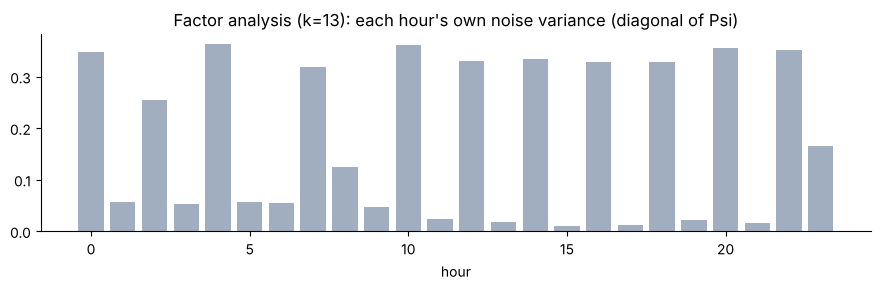

In [8]:
def pca(X):
    S = X.T @ X / (len(X) - 1)
    evals, evecs = np.linalg.eigh(S)
    order = np.argsort(evals)[::-1]
    return evals[order], evecs[:, order]

def gauss_loglik_mean(X, mean, Cov):
    return float(log_gauss(X, mean, Cov).mean())

def ppca_cov(evals, evecs, k):
    s2 = evals[k:].mean()                                             # noise = mean of discarded eigenvalues
    W = evecs[:, :k] * np.sqrt(np.maximum(evals[:k] - s2, 0))
    return W @ W.T + s2 * np.eye(len(evals))

def factor_analysis(X, k, iters=1000, tol=1e-7):
    N, D = X.shape
    xbar = X.mean(0); Xc = X - xbar; S = Xc.T @ Xc / N
    ev, U = np.linalg.eigh(S); ev, U = ev[::-1], U[:, ::-1]
    W = U[:, :k] * np.sqrt(ev[:k]); Psi = np.maximum(np.diag(S) - (W ** 2).sum(1), 1e-3)
    hist = []
    for _ in range(iters):
        G = np.linalg.inv(np.eye(k) + W.T @ (W / Psi[:, None]))      # E-step: G = (I + W^T Psi^-1 W)^-1
        Ez = Xc @ (W / Psi[:, None]) @ G                              # E[z_n] = G W^T Psi^-1 (x_n - xbar)
        Ezz = N * G + Ez.T @ Ez                                       # sum_n E[z_n z_n^T]
        W = (Xc.T @ Ez) @ np.linalg.inv(Ezz)                          # M-step
        Psi = np.maximum(np.diag(S - W @ (Ez.T @ Xc) / N), 1e-6)
        hist.append(gauss_loglik_mean(X, xbar, W @ W.T + np.diag(Psi)))
        if len(hist) > 1 and abs(hist[-1] - hist[-2]) < tol: break
    return W, Psi, xbar, hist

evals, evecs = pca(Xd)
evr = evals / evals.sum(); cum = np.cumsum(evr)
k90 = int(np.searchsorted(cum, 0.90) + 1); k_kaiser = int((evals > 1).sum())

perm = rng.permutation(len(Xd)); cut = int(0.8 * len(Xd))
A_, B_ = Xd[perm[:cut]], Xd[perm[cut:]]
evA, UA = pca(A_)
ks = list(range(1, 16))
ll_ppca = [gauss_loglik_mean(B_, A_.mean(0), ppca_cov(evA, UA, k)) for k in ks]
ll_fa = []
for k in ks:
    Wk, Pk, mk, _ = factor_analysis(A_, k)
    ll_fa.append(gauss_loglik_mean(B_, mk, Wk @ Wk.T + np.diag(Pk)))
k_ppca, k_fa = ks[int(np.argmax(ll_ppca))], ks[int(np.argmax(ll_fa))]
if k_ppca > k_fa:
    print("PPCA picks more dimensions than factor analysis: PPCA gives every hour the SAME noise variance, so it must use extra components to explain hours that are simply noisier; FA gives each hour its own noise.")

print(f"PC1 {evr[0]:.1%}, PC2 {evr[1]:.1%}, PC1+PC2 {cum[1]:.1%} of variance")
print(f"k for 90% variance: {k90} | eigenvalue > 1: {k_kaiser} | held-out PPCA: {k_ppca} | held-out factor analysis: {k_fa}")
RESULTS["pca"] = {"pc1_pct": round(100 * float(evr[0]), 2), "pc2_pct": round(100 * float(evr[1]), 2), "k90": k90, "k_kaiser": k_kaiser, "k_ppca": k_ppca, "k_fa": k_fa}

W_fa, Psi_fa, _, hist_fa = factor_analysis(Xd, k_fa)

fig, ax = plt.subplots(1, 3, figsize=(17, 3.8))
ax[0].bar(range(1, 25), 100 * evr, color="#cbd5e0", label="each component")
ax[0].plot(range(1, 25), 100 * cum, "o-", ms=3, color=COLORS[0], label="cumulative")
ax[0].axhline(90, ls="--", color="grey"); ax[0].set(title=f"Scree plot: {k90} components reach 90%", xlabel="component", ylabel="% variance"); ax[0].legend(fontsize=8)
for i in range(2):
    ax[1].plot(range(24), evecs[:, i], "o-", ms=3, color=COLORS[i], label=f"PC{i+1} ({evr[i]:.0%})")
ax[1].axhline(0, color="grey", lw=0.8); ax[1].set(title="PCA loadings by hour", xlabel="hour"); ax[1].legend(fontsize=8)
ax[2].plot(ks, ll_ppca, "o-", color=COLORS[0], label="probabilistic PCA")
ax[2].plot(ks, ll_fa, "s-", color=COLORS[1], label="factor analysis")
ax[2].set(title="Held-out log-likelihood per day", xlabel="latent dimensions k"); ax[2].legend(fontsize=8)
savefig("u3_pca_fa")

plt.figure(figsize=(9, 3)); plt.bar(range(24), Psi_fa, color="#a0aec0")
plt.title(f"Factor analysis (k={k_fa}): each hour's own noise variance (diagonal of Psi)"); plt.xlabel("hour")
savefig("u3_fa_noise")

## 7. Hierarchical clustering (agglomerative, Lance–Williams update)
Start with every day as its own cluster; repeatedly merge the closest pair; update the distance from the merged cluster (i∪j) to every other cluster k:
* single: min(d_ki, d_kj) · complete: max(d_ki, d_kj) · average: (n_i d_ki + n_j d_kj)/(n_i + n_j)
* Ward (on squared distances): [(n_i+n_k) d_ki + (n_j+n_k) d_kj − n_k d_ij] / (n_i+n_j+n_k)

 linkage cluster sizes largest share  silhouette
  single     [1410, 1]          100%      0.5461
complete    [1394, 17]           99%      0.5686
 average     [1410, 1]          100%      0.5461
    ward    [887, 524]           63%      0.1093


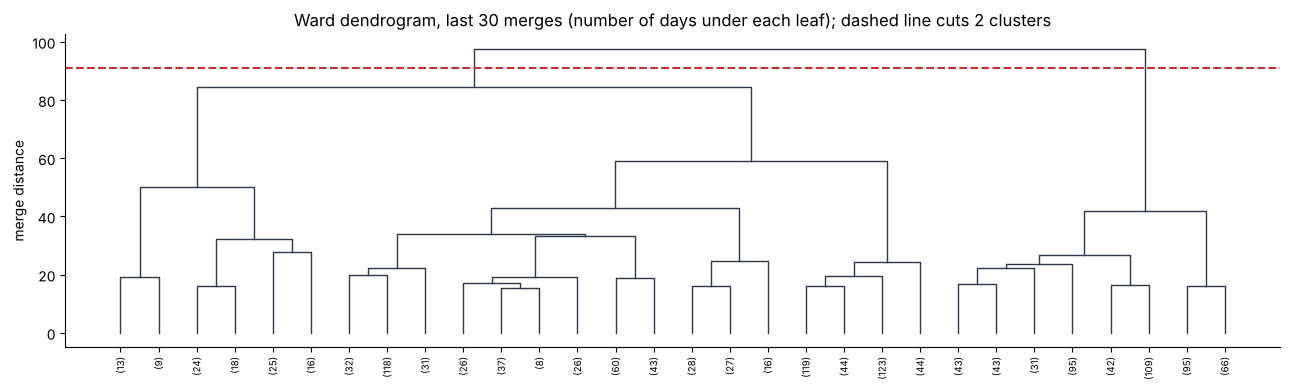

In [9]:
def agglomerative(X, method):
    n = len(X)
    D = sq_dists(X, X)
    if method != "ward": D = np.sqrt(D)
    np.fill_diagonal(D, np.inf)
    size = np.ones(n); cid = np.arange(n); Z = []
    for step in range(n - 1):
        i, j = divmod(int(np.argmin(D)), n)
        if i > j: i, j = j, i
        dij = D[i, j]
        Z.append([cid[i], cid[j], np.sqrt(dij) if method == "ward" else dij, size[i] + size[j]])
        di, dj, ni, nj = D[i].copy(), D[j].copy(), size[i], size[j]
        with np.errstate(invalid="ignore"):
            if method == "single":     new = np.minimum(di, dj)
            elif method == "complete": new = np.maximum(di, dj)
            elif method == "average":  new = (ni * di + nj * dj) / (ni + nj)
            else:                      new = ((ni + size) * di + (nj + size) * dj - size * dij) / (ni + nj + size)
        new[~np.isfinite(new)] = np.inf
        D[i, :] = new; D[:, i] = new; D[i, i] = np.inf
        D[j, :] = np.inf; D[:, j] = np.inf
        size[i] = ni + nj; cid[i] = n + step
    return np.array(Z)

def cut_tree(Z, n, K):
    members = {i: [i] for i in range(n)}
    for s in range(n - K):                                            # undo the last K-1 merges
        a, b = int(Z[s, 0]), int(Z[s, 1])
        members[n + s] = members.pop(a) + members.pop(b)
    lab = np.empty(n, int)
    for l, m in enumerate(members.values()): lab[m] = l
    return lab

def plot_dendrogram(Z, n, p, ax, cut_height=None):
    first = n - p
    def kids(c):
        return (int(Z[c - n, 0]), int(Z[c - n, 1])) if c >= n and c - n >= first else None
    xs, order = {}, []
    def walk(c):
        k = kids(c)
        if k is None:
            xs[c] = len(order); order.append(c); return 0.0
        h0, h1 = walk(k[0]), walk(k[1]); h = Z[c - n, 2]
        x0, x1 = xs[k[0]], xs[k[1]]
        ax.plot([x0, x0, x1, x1], [h0, h, h, h1], color="#2d3748", lw=1)
        xs[c] = (x0 + x1) / 2
        return h
    walk(2 * n - 2)
    sizes = [1 if c < n else int(Z[c - n, 3]) for c in order]
    ax.set_xticks(range(len(order))); ax.set_xticklabels([f"({s})" for s in sizes], rotation=90, fontsize=7)
    if cut_height is not None: ax.axhline(cut_height, ls="--", color=COLORS[3])

rows, Zs = [], {}
for method in ["single", "complete", "average", "ward"]:
    Zs[method] = agglomerative(Xd, method)
    lab = cut_tree(Zs[method], len(Xd), K)
    sizes = np.bincount(lab)
    rows.append({"linkage": method, "cluster sizes": sorted(sizes.tolist(), reverse=True), "largest share": f"{sizes.max() / len(lab):.0%}",
                 "silhouette": round(silhouette(D_eu, lab), 4) if len(sizes) > 1 else None})
show(pd.DataFrame(rows))
lab_hc = by_usage(cut_tree(Zs["ward"], len(Xd), K))

fig, ax = plt.subplots(figsize=(13, 4))
Zw = Zs["ward"]
plot_dendrogram(Zw, len(Xd), 30, ax, cut_height=(Zw[-K, 2] + Zw[-K + 1, 2]) / 2)
ax.set(title=f"Ward dendrogram, last 30 merges (number of days under each leaf); dashed line cuts {K} clusters", ylabel="merge distance")
savefig("u3_dendrogram")

## 8. Compare the three clusterings and describe the kinds of day
ARI = 1 means two methods group the days identically; 0 means no more agreement than chance.

               method  silhouette  Davies-Bouldin  ARI vs K-means
              K-means      0.2039          2.0510          1.0000
  Hierarchical (Ward)      0.1093          2.0862          0.1749
GMM (full covariance)      0.0476          3.4874          0.0900
 cluster  days  mean kWh/day  peak hour  peak kW weekend Dec-Feb Jun-Aug
       0   916          20.7         21     1.57     19%     12%     36%
       1   495          36.4         20     2.65     45%     46%      5%
All days: weekend 28%, Dec-Feb 24%, Jun-Aug 25%
Name each cluster by comparing its shares with the all-days shares.


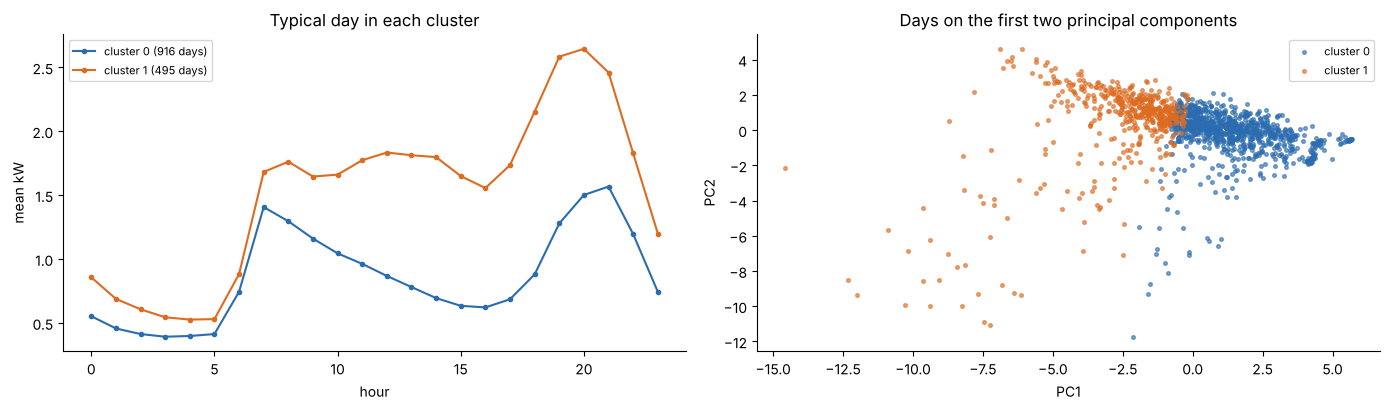

In [10]:
comp = pd.DataFrame([
    {"method": "K-means", "silhouette": silhouette(D_eu, lab_km), "Davies-Bouldin": davies_bouldin(Xd, lab_km), "ARI vs K-means": 1.0},
    {"method": "Hierarchical (Ward)", "silhouette": silhouette(D_eu, lab_hc), "Davies-Bouldin": davies_bouldin(Xd, lab_hc), "ARI vs K-means": adjusted_rand(lab_km, lab_hc)},
    {"method": f"GMM ({COV} covariance)", "silhouette": silhouette(D_eu, lab_gmm), "Davies-Bouldin": davies_bouldin(Xd, lab_gmm), "ARI vs K-means": adjusted_rand(lab_km, lab_gmm)},
]).round(4)
show(comp)
RESULTS["clustering_comparison"] = comp.to_dict(orient="records")

FINAL = lab_km
dates = profiles.index
desc = []
for c in range(K):
    m = FINAL == c; prof = P[m].mean(0)
    desc.append({"cluster": c, "days": int(m.sum()), "mean kWh/day": round(float(daily_kwh[m].mean()), 1),
                 "peak hour": int(prof.argmax()), "peak kW": round(float(prof.max()), 2),
                 "weekend": f"{(dates[m].dayofweek >= 5).mean():.0%}",
                 "Dec-Feb": f"{dates[m].month.isin([12, 1, 2]).mean():.0%}",
                 "Jun-Aug": f"{dates[m].month.isin([6, 7, 8]).mean():.0%}"})
show(pd.DataFrame(desc))
RESULTS["clusters"] = desc
print(f"All days: weekend {(dates.dayofweek >= 5).mean():.0%}, Dec-Feb {dates.month.isin([12,1,2]).mean():.0%}, Jun-Aug {dates.month.isin([6,7,8]).mean():.0%}")
print("Name each cluster by comparing its shares with the all-days shares.")

Zp = Xd @ evecs[:, :2]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for c in range(K):
    m = FINAL == c
    ax[0].plot(range(24), P[m].mean(0), "o-", ms=3, color=COLORS[c], label=f"cluster {c} ({m.sum()} days)")
    ax[1].scatter(Zp[m, 0], Zp[m, 1], s=7, alpha=0.6, color=COLORS[c], label=f"cluster {c}")
ax[0].set(title="Typical day in each cluster", xlabel="hour", ylabel="mean kW"); ax[0].legend(fontsize=8)
ax[1].set(title="Days on the first two principal components", xlabel="PC1", ylabel="PC2"); ax[1].legend(fontsize=8)
savefig("u3_clusters")

---
# Unit 4: the hourly load as a sequence
## 9. Hourly series, chronological split and three load levels
* Gaps of up to 2 hours are filled by straight-line interpolation. Longer gaps split the series into separate **segments**, so no model links two hours across a missing stretch.
* **Chronological split:** the first 80 % of hours train every model; the last 20 % test them. A random split would let the models see the future.
* **Low / Medium / High** = the terciles of the training hours, so each level holds one third of training hours.

In [11]:
h = hourly.interpolate(limit=2, limit_area="inside")
split_time = h.index[int(0.8 * len(h))]

def segments(series, min_len=48):
    s = series.dropna()
    gap = np.diff(s.index.values).astype("timedelta64[h]").astype(int)
    breaks = np.where(gap > 1)[0] + 1
    return [s.iloc[p] for p in np.split(np.arange(len(s)), breaks) if len(p) >= min_len]

train_segs = segments(h[h.index < split_time])
test_segs = segments(h[h.index >= split_time])
train_all = pd.concat(train_segs)
print(f"Split at {split_time}: {len(train_all):,} training hours in {len(train_segs)} segments; "
      f"{sum(len(s) for s in test_segs):,} test hours in {len(test_segs)} segments")

thr = np.quantile(train_all.values, [1 / 3, 2 / 3])
def level(x): return np.digitize(x, thr)          # 0 = Low, 1 = Medium, 2 = High
level_mean_kW = np.array([train_all.values[level(train_all.values) == k].mean() for k in range(3)])
STATE_NAMES = ["Low", "Medium", "High"]
STATE_COLORS = ["#2f855a", "#d69e2e", "#c53030"]
print(f"Low < {thr[0]:.3f} kW <= Medium < {thr[1]:.3f} kW <= High")
RESULTS["level_thresholds_kW"] = [round(float(t), 3) for t in thr]

Split at 2010-02-11 16:00:00: 27,492 training hours in 5 segments; 6,681 test hours in 4 segments
Low < 0.397 kW <= Medium < 1.398 kW <= High


## 10. Markov chain on the observed levels
Markov property: the next level depends only on the current level. P[i, j] = (number of i → j transitions) / (number of transitions out of i), counted in the training segments.

In [12]:
counts = np.zeros((3, 3))
for s in train_segs:
    L = level(s.values)
    np.add.at(counts, (L[:-1], L[1:]), 1)
T_mc = counts / counts.sum(1, keepdims=True)

evals_mc, evecs_mc = np.linalg.eig(T_mc.T)
stat = np.real(evecs_mc[:, np.argmin(np.abs(evals_mc - 1))]); stat = stat / stat.sum()
show(pd.DataFrame(T_mc.round(3), columns=[f"to {n}" for n in STATE_NAMES]).assign(**{"from": STATE_NAMES})[["from"] + [f"to {n}" for n in STATE_NAMES]])
print("Stationary distribution pi = pi P:", dict(zip(STATE_NAMES, stat.round(3))))
print("Two-step example: P(High in 2 hours | Low now) = (P^2)[Low, High] =", round(float((T_mc @ T_mc)[0, 2]), 3))
RESULTS["markov_chain_P"] = T_mc.round(4).tolist()

  from  to Low  to Medium  to High
   Low   0.747      0.221    0.032
Medium   0.235      0.529    0.236
  High   0.018      0.250    0.732
Stationary distribution pi = pi P: {'Low': np.float64(0.334), 'Medium': np.float64(0.333), 'High': np.float64(0.333)}
Two-step example: P(High in 2 hours | Low now) = (P^2)[Low, High] = 0.099


## 11. Hidden Markov model trained with Baum–Welch (from scratch)
Three **hidden** states; each emits log kW from its own Gaussian (log, because load is right-skewed). λ = (π, A, μ, σ).
* **E-step:** scaled forward–backward gives γ_t(j) = P(z_t = j | x) and ξ_t(i, j) = P(z_{t−1} = i, z_t = j | x).
* **M-step:** π = γ₁, a_ij = Σ_t ξ_t(i, j) / Σ_t Σ_k ξ_t(i, k), μ_j = Σ_t γ_t(j) x_t / Σ_t γ_t(j), σ²_j = Σ_t γ_t(j)(x_t − μ_j)² / Σ_t γ_t(j).
* Scaling: after each forward step α_t is divided by c_t = Σ_j α_t(j), so ln P(x) = Σ_t ln c_t and nothing underflows.

Baum-Welch iterations: 48; log-likelihood never decreased: True
 state  typical kW = exp(mu)  sd of log kW  stays this many hours on average = 1/(1-a_ii)  initial pi
   Low                 0.289         0.251                                            4.4       0.000
Medium                 0.735         0.433                                            2.0       0.226
  High                 1.928         0.354                                            5.3       0.774
  from  to Low  to Medium  to High
   Low   0.775      0.200    0.025
Medium   0.267      0.505    0.229
  High   0.005      0.185    0.810
Why scaling: unscaled P(x) over 3585 test hours = 0.0 (underflow); scaled log P(x) = -2580.5


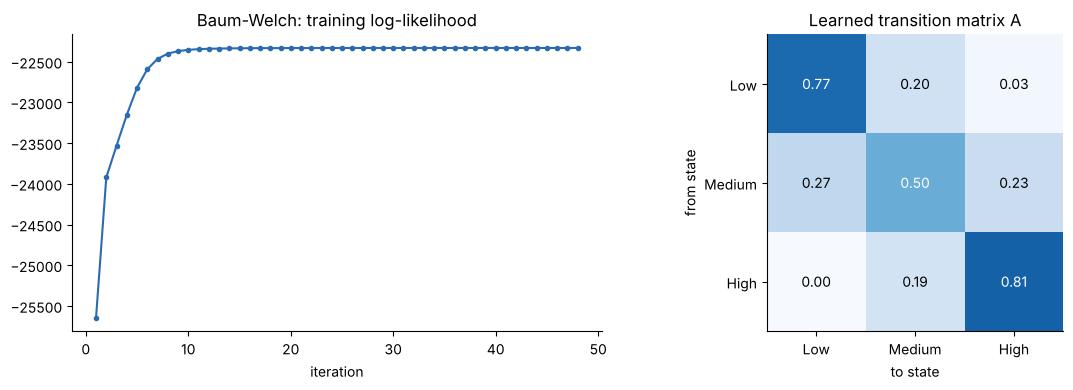

In [13]:
def norm_logpdf(x, mu, sd):
    return -0.5 * np.log(2 * np.pi * sd ** 2) - (x - mu) ** 2 / (2 * sd ** 2)

def emissions(x, mu, sd):
    return np.exp(norm_logpdf(x[:, None], mu[None, :], sd[None, :]))          # T x N, b_j(x_t)

def forward_scaled(x, pi, A, mu, sd):
    B = emissions(x, mu, sd); T, N = B.shape
    alpha = np.zeros((T, N)); c = np.zeros(T)
    a = pi * B[0]; c[0] = a.sum(); alpha[0] = a / c[0]
    for t in range(1, T):
        a = (alpha[t - 1] @ A) * B[t]                                          # alpha_t(j) = [sum_i alpha_{t-1}(i) a_ij] b_j(x_t)
        c[t] = a.sum(); alpha[t] = a / c[t]
    return alpha, c, B

def backward_scaled(B, A, c):
    T, N = B.shape; beta = np.ones((T, N))
    for t in range(T - 2, -1, -1):
        beta[t] = (A @ (B[t + 1] * beta[t + 1])) / c[t + 1]                    # beta_t(i) = sum_j a_ij b_j(x_{t+1}) beta_{t+1}(j)
    return beta

def baum_welch(segs, N=3, iters=500, tol=1e-7):
    xall = np.concatenate(segs)
    mu = np.quantile(xall, [1 / 6, 1 / 2, 5 / 6]); sd = np.full(N, xall.std() / 2)
    A = np.full((N, N), 0.1 / (N - 1)); np.fill_diagonal(A, 0.9); pi = np.full(N, 1.0 / N)
    hist = []
    for _ in range(iters):
        g0 = np.zeros(N); xi_sum = np.zeros((N, N)); g_sum = np.zeros(N); gx = np.zeros(N); gxx = np.zeros(N); ll = 0.0
        for x in segs:                                                         # E-step on every segment
            alpha, c, B = forward_scaled(x, pi, A, mu, sd)
            beta = backward_scaled(B, A, c)
            gamma = alpha * beta
            xi = alpha[:-1, :, None] * A[None, :, :] * (B[1:] * beta[1:])[:, None, :] / c[1:, None, None]
            g0 += gamma[0]; xi_sum += xi.sum(0)
            g_sum += gamma.sum(0); gx += gamma.T @ x; gxx += gamma.T @ (x ** 2)
            ll += np.log(c).sum()
        hist.append(float(ll))
        pi = g0 / g0.sum()                                                     # M-step
        A = xi_sum / xi_sum.sum(1, keepdims=True)
        mu = gx / g_sum
        sd = np.sqrt(np.maximum(gxx / g_sum - mu ** 2, 1e-6))
        if len(hist) > 1 and abs(hist[-1] - hist[-2]) < tol * abs(hist[-1]): break
    order = np.argsort(mu)                                                     # Low, Medium, High
    return pi[order], A[np.ix_(order, order)], mu[order], sd[order], hist

def viterbi(x, pi, A, mu, sd):
    lB = norm_logpdf(x[:, None], mu[None, :], sd[None, :]); lA = np.log(A + 1e-300); T, N = lB.shape
    delta = np.log(pi + 1e-300) + lB[0]; psi = np.zeros((T, N), int)
    for t in range(1, T):
        m = delta[:, None] + lA                                                # delta_{t-1}(i) + ln a_ij
        psi[t] = m.argmax(0); delta = m.max(0) + lB[t]
    path = np.zeros(T, int); path[-1] = delta.argmax()
    for t in range(T - 1, 0, -1):
        path[t - 1] = psi[t, path[t]]                                         # backtrack
    return path, float(delta.max())

train_logs = [np.log(s.values) for s in train_segs]
pi_h, A_h, mu_h, sd_h, hist_bw = baum_welch(train_logs)
print(f"Baum-Welch iterations: {len(hist_bw)}; log-likelihood never decreased: {bool(np.all(np.diff(hist_bw) >= -1e-6))}")
show(pd.DataFrame({"state": STATE_NAMES, "typical kW = exp(mu)": np.exp(mu_h).round(3), "sd of log kW": sd_h.round(3),
                   "stays this many hours on average = 1/(1-a_ii)": (1 / (1 - np.diag(A_h))).round(1), "initial pi": pi_h.round(3)}))
show(pd.DataFrame(A_h.round(3), columns=[f"to {n}" for n in STATE_NAMES]).assign(**{"from": STATE_NAMES})[["from"] + [f"to {n}" for n in STATE_NAMES]])
RESULTS["hmm"] = {"A": A_h.round(4).tolist(), "state_kW": np.exp(mu_h).round(3).tolist(), "sd_log": sd_h.round(3).tolist(), "iterations": len(hist_bw)}

seg = max(test_segs, key=len); x = np.log(seg.values)
alpha, c, B = forward_scaled(x, pi_h, A_h, mu_h, sd_h)
a_ = pi_h * B[0]
for t in range(1, len(x)):
    a_ = (a_ @ A_h) * B[t]
print(f"Why scaling: unscaled P(x) over {len(x)} test hours = {a_.sum()} (underflow); scaled log P(x) = {np.log(c).sum():.1f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(1, len(hist_bw) + 1), hist_bw, "o-", ms=3, color=COLORS[0]); ax[0].set(title="Baum-Welch: training log-likelihood", xlabel="iteration")
ax[1].imshow(A_h, cmap="Blues", vmin=0, vmax=1)
for i in range(3):
    for j in range(3):
        ax[1].text(j, i, f"{A_h[i, j]:.2f}", ha="center", va="center", color="white" if A_h[i, j] > 0.5 else "black")
ax[1].set_xticks(range(3)); ax[1].set_xticklabels(STATE_NAMES); ax[1].set_yticks(range(3)); ax[1].set_yticklabels(STATE_NAMES)
ax[1].set(xlabel="to state", ylabel="from state", title="Learned transition matrix A")
savefig("u4_hmm")

## 12. Viterbi decoding: the most likely state sequence
Viterbi is the forward algorithm with the sum replaced by a max, in logs: δ_t(j) = max_i [δ_{t−1}(i) + ln a_ij] + ln b_j(x_t), keeping a back-pointer ψ_t(j) to the best i, then tracing back from the best final state. Forward–backward gives the most likely state **at each hour**; Viterbi gives the most likely **whole path**.

Viterbi path vs hour-by-hour most likely state (from forward-backward): same on 98.0% of hours
Share of test hours in each decoded state: {'Low': np.float64(0.3603905160390516), 'Medium': np.float64(0.3302649930264993), 'High': np.float64(0.3093444909344491)}


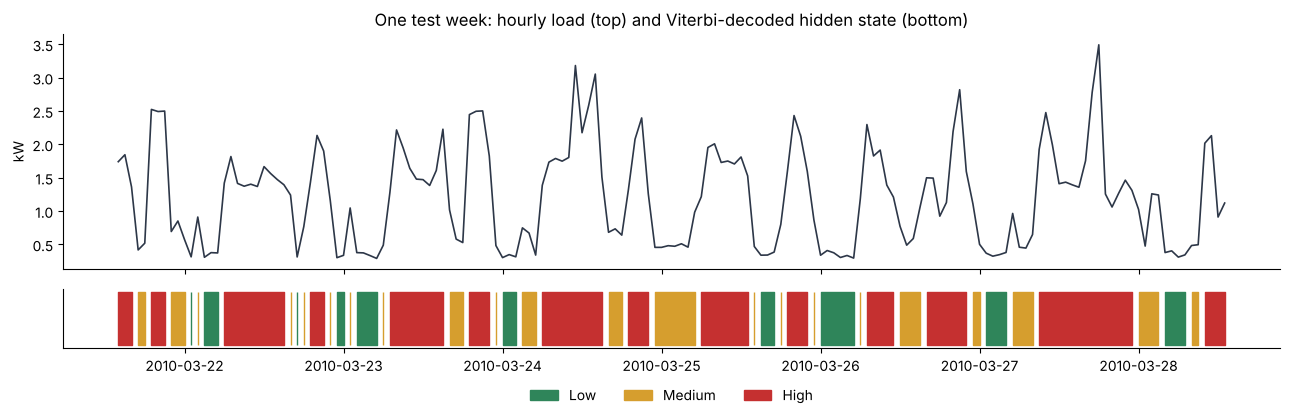

In [14]:
path, best_logp = viterbi(x, pi_h, A_h, mu_h, sd_h)
gamma_test = alpha * backward_scaled(B, A_h, c)
agree = float((path == gamma_test.argmax(1)).mean())
print(f"Viterbi path vs hour-by-hour most likely state (from forward-backward): same on {agree:.1%} of hours")
print("Share of test hours in each decoded state:", dict(zip(STATE_NAMES, np.bincount(path, minlength=3) / len(path))))
RESULTS["viterbi_vs_posterior_agreement"] = round(agree, 4)

week = seg.iloc[:168]; wpath = path[:168]
fig, ax = plt.subplots(2, 1, figsize=(13, 4.3), sharex=True, gridspec_kw={"height_ratios": [4, 1]})
ax[0].plot(week.index, week.values, color="#2d3748", lw=1.2)
ax[0].set(ylabel="kW", title="One test week: hourly load (top) and Viterbi-decoded hidden state (bottom)")
for s in range(3):
    ax[1].fill_between(week.index, 0, 1, where=(wpath == s), step="post", color=STATE_COLORS[s], label=STATE_NAMES[s])
ax[1].set_yticks([]); ax[1].legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.45), frameon=False)
savefig("u4_viterbi_week")

## 13. Linear dynamical system: Kalman filter, RTS smoother and EM
A **continuous** hidden state z_t = how far this hour's load is above or below the usual load for that hour of day, s_h (the training mean for hour h):
z_t = a z_{t−1} + w_t, w_t ~ N(0, Q)  ·  x_t = s_{h(t)} + z_t + v_t, v_t ~ N(0, R).
*a* is how much of an unusual hour carries into the next, Q how much new disturbance arrives each hour, R the measurement noise. The Kalman filter predicts then updates using only the past; the RTS smoother runs backwards so each estimate uses the whole sequence; EM learns a, Q and R from the smoothed moments.

EM for the LDS: 500 iterations (stopped at the iteration limit); log-likelihood never decreased: True
a = 0.703, Q = 0.3230, R = 0.0201  ->  70% of an unusual hour carries into the next hour


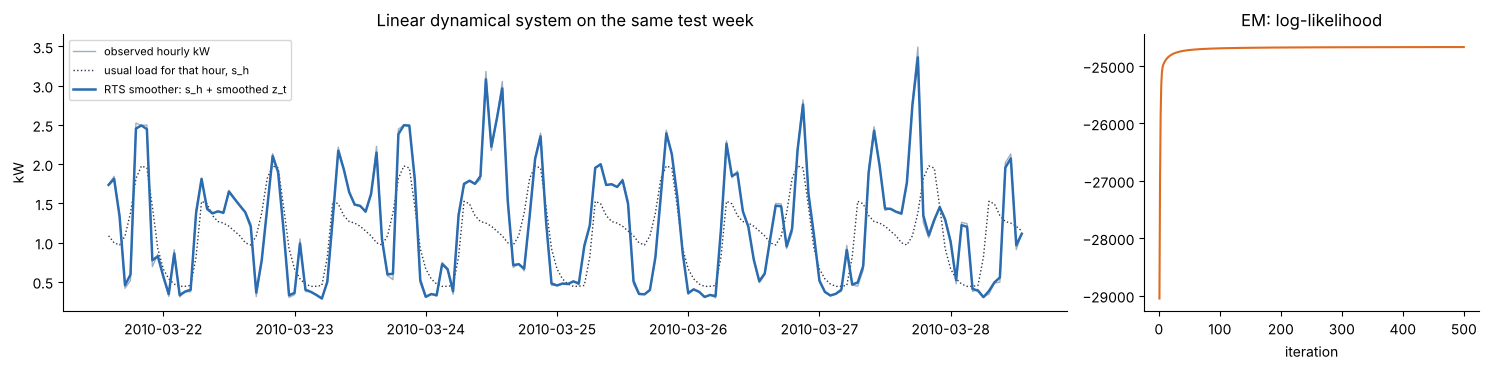

In [15]:
season = train_all.groupby(train_all.index.hour).mean()                        # s_h, from training hours only
def deseason(s): return s.values - season.loc[s.index.hour].values

def kalman_filter(y, a, Q, R, m0=0.0, P0=None):
    T = len(y); m = np.zeros(T); P = np.zeros(T); mp = np.zeros(T); Pp = np.zeros(T); ll = 0.0
    P0 = Q / max(1 - a * a, 1e-6) if P0 is None else P0                       # stationary variance of z
    for t in range(T):
        mp[t], Pp[t] = (m0, P0) if t == 0 else (a * m[t - 1], a * a * P[t - 1] + Q)     # predict
        S = Pp[t] + R; K = Pp[t] / S; e = y[t] - mp[t]
        ll += -0.5 * (np.log(2 * np.pi * S) + e * e / S)
        m[t] = mp[t] + K * e; P[t] = (1 - K) * Pp[t]                               # update
    return m, P, mp, Pp, ll

def rts_smoother(m, P, mp, Pp, a):
    T = len(m); ms = m.copy(); Ps = P.copy(); J = np.zeros(T)
    for t in range(T - 2, -1, -1):
        J[t] = a * P[t] / Pp[t + 1]
        ms[t] = m[t] + J[t] * (ms[t + 1] - mp[t + 1])
        Ps[t] = P[t] + J[t] ** 2 * (Ps[t + 1] - Pp[t + 1])
    P_cross = J[:-1] * Ps[1:]                                                      # Cov(z_{t+1}, z_t | all data)
    return ms, Ps, P_cross

def lds_em(segs, iters=500, tol=1e-8):
    a, Q, R = 0.5, float(np.var(np.concatenate(segs))) / 2, float(np.var(np.concatenate(segs))) / 2
    hist = []
    for _ in range(iters):
        Szz1 = Sz1 = Szz = Sres = 0.0; nQ = nR = 0; ll = 0.0
        for y in segs:
            m, P, mp, Pp, l = kalman_filter(y, a, Q, R)
            ms, Ps, Pc = rts_smoother(m, P, mp, Pp, a)
            Ezz = ms ** 2 + Ps                                                     # E[z_t^2]
            Ezz1 = ms[1:] * ms[:-1] + Pc                                           # E[z_t z_{t-1}]
            Szz1 += Ezz1.sum(); Sz1 += Ezz[:-1].sum(); Szz += Ezz[1:].sum(); nQ += len(y) - 1
            Sres += np.sum((y - ms) ** 2 + Ps); nR += len(y); ll += l
        hist.append(float(ll))
        a = Szz1 / Sz1                                                             # M-step
        Q = (Szz - a * Szz1) / nQ
        R = max(Sres / nR, 1e-8)
        if len(hist) > 1 and abs(hist[-1] - hist[-2]) < tol * abs(hist[-1]): break
    return a, Q, R, hist

train_dev = [deseason(s) for s in train_segs]
a_k, Q_k, R_k, hist_k = lds_em(train_dev)
print(f"EM for the LDS: {len(hist_k)} iterations ({'converged' if len(hist_k) < 500 else 'stopped at the iteration limit'}); "
      f"log-likelihood never decreased: {bool(np.all(np.diff(hist_k) >= -1e-6))}")
print(f"a = {a_k:.3f}, Q = {Q_k:.4f}, R = {R_k:.4f}  ->  {100 * a_k:.0f}% of an unusual hour carries into the next hour")
RESULTS["lds"] = {"a": round(a_k, 4), "Q": round(Q_k, 5), "R": round(R_k, 5), "em_iterations": len(hist_k)}

wk_dev = deseason(week); wk_s = season.loc[week.index.hour].values
mf, Pf, mpf, Ppf, _ = kalman_filter(wk_dev, a_k, Q_k, R_k)
ms_w, Ps_w, _ = rts_smoother(mf, Pf, mpf, Ppf, a_k)
fig, ax = plt.subplots(1, 2, figsize=(15, 3.8), gridspec_kw={"width_ratios": [3, 1]})
ax[0].plot(week.index, week.values, color="#a0aec0", lw=1, label="observed hourly kW")
ax[0].plot(week.index, wk_s, color="#2d3748", lw=1, ls=":", label="usual load for that hour, s_h")
ax[0].plot(week.index, wk_s + ms_w, color=COLORS[0], lw=1.8, label="RTS smoother: s_h + smoothed z_t")
ax[0].set(ylabel="kW", title="Linear dynamical system on the same test week"); ax[0].legend(fontsize=8)
ax[1].plot(range(1, len(hist_k) + 1), hist_k, color=COLORS[1]); ax[1].set(title="EM: log-likelihood", xlabel="iteration")
savefig("u4_lds_week")

## 14. Comparison of the Unit 4 models: next-hour prediction on the test set
Every model uses only hours up to t to predict hour t + 1.
* **HMM:** the scaled forward variable α_t = P(z_t | x_1…x_t); then P(z_{t+1}) = α_t A. Predicted level = the level with the highest probability after integrating each state's Gaussian over the Low/Medium/High thresholds; predicted kW = Σ_j P(z_{t+1} = j) · E[kW | j], with E[kW | j] = exp(μ_j + σ_j²/2).
* **Kalman (LDS):** predicted kW = s_{h(t+1)} + a · m_t, where m_t is the filtered state at hour t.
* **Markov chain:** predicted level = argmax_j P[level_t, j]; predicted kW = Σ_j P[level_t, j] · (mean training kW of level j).
* **Baselines:** persistence (next hour = this hour) and the training average for that hour of day.

                         model  level accuracy  MAE kW  RMSE kW
        Persistence (baseline)          0.6313  0.3945   0.6003
Hour-of-day average (baseline)          0.5124  0.5076   0.6678
        Markov chain on levels          0.6313  0.4462   0.5863
       HMM: forward filter + A          0.6001  0.4384   0.5855
     Kalman filter (AR(1) LDS)          0.6114  0.3658   0.5135
Markov chain on levels: level accuracy +0.0 points, MAE +0.052 kW vs persistence
HMM: forward filter + A: level accuracy -3.1 points, MAE +0.044 kW vs persistence
Kalman filter (AR(1) LDS): level accuracy -2.0 points, MAE -0.029 kW vs persistence
Test hours compared: 6,677. Report these margins honestly, whichever way they go.


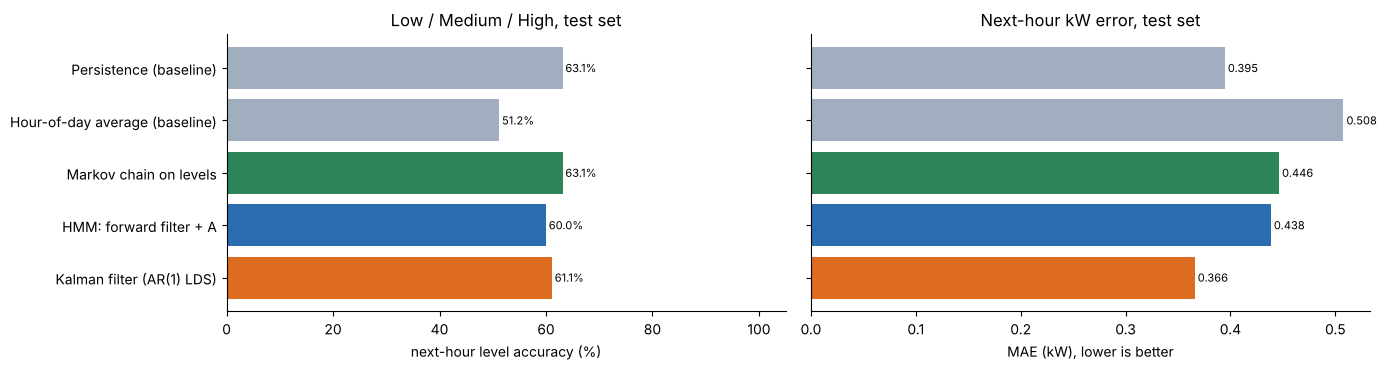

Saved results.json and figures/


In [16]:
def std_normal_cdf(z):
    # Phi(z) via the error function, written with a rational approximation (Abramowitz & Stegun 7.1.26, |error| < 1.5e-7)
    s = np.sign(z); a = np.abs(z) / np.sqrt(2)
    t = 1 / (1 + 0.3275911 * a)
    erf = 1 - t * (0.254829592 + t * (-0.284496736 + t * (1.421413741 + t * (-1.453152027 + t * 1.061405429)))) * np.exp(-a * a)
    return 0.5 * (1 + s * erf)

edges = np.r_[-np.inf, np.log(thr), np.inf]
P_level_given_state = np.array([[std_normal_cdf((edges[k + 1] - mu_h[j]) / sd_h[j]) - std_normal_cdf((edges[k] - mu_h[j]) / sd_h[j])
                                 for k in range(3)] for j in range(3)])
state_mean_kW = np.exp(mu_h + sd_h ** 2 / 2)
hour_mean = train_all.groupby(train_all.index.hour).mean()
hour_level = pd.Series(level(train_all.values), index=train_all.index).groupby(train_all.index.hour).agg(lambda v: int(np.bincount(v, minlength=3).argmax()))

keys = ["true_lvl", "true_kW", "hmm_lvl", "hmm_kW", "kal_lvl", "kal_kW", "mc_lvl", "mc_kW", "per_lvl", "per_kW", "hod_lvl", "hod_kW"]
rec = {k: [] for k in keys}
for s in test_segs:
    v = s.values; L = level(v)
    al, _, _ = forward_scaled(np.log(v), pi_h, A_h, mu_h, sd_h)
    p_next = al[:-1] @ A_h
    rec["hmm_lvl"] += list((p_next @ P_level_given_state).argmax(1)); rec["hmm_kW"] += list(p_next @ state_mean_kW)
    mk, _, _, _, _ = kalman_filter(deseason(s), a_k, Q_k, R_k)
    kal_pred = season.loc[s.index[1:].hour].values + a_k * mk[:-1]
    rec["kal_kW"] += list(kal_pred); rec["kal_lvl"] += list(level(kal_pred))
    rec["mc_lvl"] += list(T_mc[L[:-1]].argmax(1)); rec["mc_kW"] += list(T_mc[L[:-1]] @ level_mean_kW)
    rec["per_lvl"] += list(L[:-1]); rec["per_kW"] += list(v[:-1])
    nh = s.index[1:].hour
    rec["hod_lvl"] += list(hour_level.loc[nh].values); rec["hod_kW"] += list(hour_mean.loc[nh].values)
    rec["true_lvl"] += list(L[1:]); rec["true_kW"] += list(v[1:])
rec = {k: np.array(v, dtype=float) for k, v in rec.items()}

def acc(k): return float((rec[k] == rec["true_lvl"]).mean())
def mae_(k): return float(np.abs(rec[k] - rec["true_kW"]).mean())
def rmse_(k): return float(np.sqrt(((rec[k] - rec["true_kW"]) ** 2).mean()))
models = [("Persistence (baseline)", "per"), ("Hour-of-day average (baseline)", "hod"), ("Markov chain on levels", "mc"),
          ("HMM: forward filter + A", "hmm"), ("Kalman filter (AR(1) LDS)", "kal")]
cmp4 = pd.DataFrame([{"model": n, "level accuracy": acc(k + "_lvl"), "MAE kW": mae_(k + "_kW"), "RMSE kW": rmse_(k + "_kW")} for n, k in models]).round(4)
show(cmp4)
RESULTS["unit4_comparison"] = cmp4.to_dict(orient="records")
base = cmp4.iloc[0]
for _, r in cmp4.iloc[2:].iterrows():
    print(f"{r['model']}: level accuracy {100 * (r['level accuracy'] - base['level accuracy']):+.1f} points, MAE {r['MAE kW'] - base['MAE kW']:+.3f} kW vs persistence")
print(f"Test hours compared: {len(rec['true_lvl']):,}. Report these margins honestly, whichever way they go.")

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
cols = ["#a0aec0", "#a0aec0", COLORS[2], COLORS[0], COLORS[1]]
ax[0].barh(cmp4["model"], 100 * cmp4["level accuracy"], color=cols); ax[0].invert_yaxis()
for i, v_ in enumerate(100 * cmp4["level accuracy"]): ax[0].text(v_ + 0.5, i, f"{v_:.1f}%", va="center", fontsize=8)
ax[0].set(xlabel="next-hour level accuracy (%)", title="Low / Medium / High, test set"); ax[0].set_xlim(0, 105)
ax[1].barh(cmp4["model"], cmp4["MAE kW"], color=cols); ax[1].invert_yaxis(); ax[1].set_yticklabels([])
for i, v_ in enumerate(cmp4["MAE kW"]): ax[1].text(v_, i, f" {v_:.3f}", va="center", fontsize=8)
ax[1].set(xlabel="MAE (kW), lower is better", title="Next-hour kW error, test set")
savefig("u4_comparison")

with open("results.json", "w") as f:
    json.dump(RESULTS, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("Saved results.json and figures/")